# Detecting Fraudulent Websites from the URL and its Page Signals

### F21DL Data Mining and Machine Learning, Group Coursework

| Item | Detail |
|---|---|
| Project title | Trust or trick? Detecting fraudulent and scam websites from URL and page signals |
| Coursework topic | Topic 11, predict whether a website is fraudulent or a scam |
| Dataset | PhiUSIIL Phishing URL Dataset, UCI Machine Learning Repository, dataset 967 |
| Licence | CC BY 4.0, Prasad and Chandra (2024) |
| Repository | https://github.com/Sakib-Dalal/DMML-CourseWork01 |

This notebook holds all the work for requirements R1 to R4. Each step starts with a
short explanation, then the code that does the work. Graphs appear only where the
coursework asks for them.

## Steps

| Step | Content | Requirement |
|---|---|---|
| 1 | Questions and hypotheses | R1 |
| 2 | Imports and settings | setup |
| 3 | Load the dataset | R2 |
| 4 | First look at the data | R2 |
| 5 | Cleaning and preprocessing | R2 |
| 6 | Exploratory data analysis | R2 |
| 7 | Feature selection and evaluation | R2 |
| 8 | Split and scaling | R2 |
| 9 | Clustering with K-Means and EM | R2 |
| 10 | Classical models | R3 |
| 11 | Decision trees in practice | R3 |
| 12 | Neural networks | R4 |
| 13 | Final comparison | R3, R4 |
| 14 | Conclusions and references | all |

# Step 1: Questions and hypotheses (R1)

A phishing website is a fake page. It copies a bank, a delivery company or a payment
service. The visitor types a password or a card number, and the attacker keeps it.
A security team cannot read every URL by hand, so a model must score each website
and put the suspicious ones into a review queue.

Two kinds of evidence exist for one website:

1. The URL string. It is short, free to collect and available before anyone visits the page.
2. Signals from the page behind the URL. Examples are the page size, the number of
   images and whether the page has a login form.

The dataset holds both. The project asks which kind of evidence gives the signal.

## Questions

1. RQ1. How accurately can a model separate phishing websites from legitimate ones?
2. RQ2. Which features carry the signal? Are they lexical features of the URL, or
   features of the page?
3. RQ3. Do the groups that an unsupervised algorithm finds match the real label?
4. RQ4. Does a neural network beat the classical models on this data? Does a
   pretrained language model that reads only the URL text add new information?

## Hypotheses

1. H1. The supplied features give very high accuracy, above 95%. Phishing pages have a
   different structure from ordinary pages.
2. H2. Features of the page dominate the ranking. A phishing page is usually one small
   file that loads its images and scripts from other servers.
3. H3. Clusters match the label only in part. A small legitimate site and a phishing
   page can look alike from the outside.
4. H4. A neural network matches but does not beat the tree ensembles. The relation
   between the features and the label is mostly a set of threshold rules.

## One note on three features

Three supplied features compare the URL with the official URL or title of the brand.
They are `URLSimilarityIndex`, `URLTitleMatchScore` and `DomainTitleMatchScore`.
For a legitimate site this comparison is with itself, so the score is 100. These three
columns therefore come close to a copy of the label. Step 7 removes them from the model
and explains the reason.

# Step 2: Imports and settings

The course recommends the frameworks from the labs. This notebook uses pandas for the
data table, scikit-learn for the models, matplotlib and seaborn for graphs, and torch
with transformers for the neural network step.

One random seed is fixed, so each run gives the same numbers.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

SAMPLE_SIZE = 24000   # rows used for the models, the full file has about 236k
TEST_SIZE = 0.30
CLASS_NAMES = ["Phishing", "Legitimate"]

# these compare the URL with the brand's official URL or title, see Step 1
SIMILARITY_FEATURES = ["URLSimilarityIndex", "URLTitleMatchScore", "DomainTitleMatchScore"]

# Step 3: Load the dataset (R2)

The dataset is one CSV file in the `Datasets` folder of the repository.

The helper below finds the file from any folder inside the project. It walks up from the
current folder until it finds `Datasets/<file name>`.

In [3]:
DATASET_FILE = "PhiUSIIL_Phishing_URL_Dataset.csv"


def find_dataset(filename):
    folder = os.getcwd()
    for _ in range(5):
        candidate = os.path.join(folder, "Datasets", filename)
        if os.path.exists(candidate):
            return candidate
        folder = os.path.dirname(folder)
    raise FileNotFoundError("Could not find Datasets/" + filename)


DATA_PATH = find_dataset(DATASET_FILE)
print("Dataset path:", DATA_PATH)

Dataset path: /Users/sakibdalal/Projects/DMML-CourseWork01/Datasets/PhiUSIIL_Phishing_URL_Dataset.csv


In [4]:
df = pd.read_csv(DATA_PATH)

print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

Rows    : 235795
Columns : 56


In [5]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


The columns fall into four groups.

- Identifiers and text: `FILENAME`, `URL`, `Domain`, `TLD`, `Title`.
- Target: `label`. The value 1 means legitimate and 0 means phishing.
- Lexical features of the URL: `URLLength`, `NoOfSubDomain`, `IsHTTPS`,
  `SpacialCharRatioInURL`.
- Features of the page: `LineOfCode`, `NoOfImage`, `NoOfCSS`, `NoOfJS`,
  `HasPasswordField`, `NoOfExternalRef`.

# Step 4: First look at the data (R2)

Three points come before any change: the data types, the summary statistics and the
balance of the two classes.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


In [8]:
df["label"].value_counts()

label
1    134850
0    100945
Name: count, dtype: int64

The file holds 134,850 legitimate websites and 100,945 phishing websites. The split is
57 percent against 43 percent, so the classes are almost balanced.

Accuracy alone is still not enough for a security tool. Every model below also reports
precision, recall, F1 and ROC-AUC.

# Step 5: Cleaning and preprocessing (R2)

Five decisions are made here.

1. Remove duplicate URLs. One page can be captured more than once. A copy in both the
   training set and the test set makes the score look better than it is.
2. Make sure that no value is missing. A missing value needs an invented value in its place.
3. Drop each column that holds one single value. Such a column cannot separate the classes.
4. Drop the identifier and text columns. They are not numbers, so the models cannot use
   them. The `URL` column is kept apart for the text models in Step 12.
5. Encode the top level domain as a number. The domain ending `xyz` behaves differently
   from `gov`, and every model needs numbers.

In [9]:
print("Duplicate rows :", df.duplicated().sum())
print("Duplicate URLs :", df["URL"].duplicated().sum())

df = df.drop_duplicates(subset="URL").reset_index(drop=True)
print("Rows after removing duplicate URLs:", len(df))

Duplicate rows : 0
Duplicate URLs : 425


Rows after removing duplicate URLs: 235370


In [10]:
missing = df.isna().sum()
print("Total missing values:", missing.sum())
print(missing[missing > 0])

Total missing values: 0
Series([], dtype: int64)


No value is missing, so no value needs an estimate. The dataset creator removed the
incomplete captures instead.

In [11]:
constant_columns = [column for column in df.columns if df[column].nunique() == 1]
print("Columns with a single value:", constant_columns)

df = df.drop(columns=constant_columns)
print("Shape after removing constant columns:", df.shape)

Columns with a single value: []
Shape after removing constant columns: (235370, 56)


In [12]:
# keep the raw URL in its own Series, the same row index stays with it
url_table = df.pop("URL")

df = df.drop(columns=["FILENAME", "Domain", "Title"])
print("Shape of the numeric table:", df.shape)

Shape of the numeric table: (235370, 52)


In [13]:
from sklearn.preprocessing import LabelEncoder

tld_encoder = LabelEncoder()
df["TLDCode"] = tld_encoder.fit_transform(df["TLD"])
df = df.drop(columns=["TLD"])

print("Shape after encoding the TLD:", df.shape)

Shape after encoding the TLD: (235370, 52)


In [14]:
for name, values in df.items():
    print(name, "->", values.dtype)

URLLength -> int64
DomainLength -> int64
IsDomainIP -> int64
URLSimilarityIndex -> float64
CharContinuationRate -> float64
TLDLegitimateProb -> float64
URLCharProb -> float64
TLDLength -> int64
NoOfSubDomain -> int64
HasObfuscation -> int64
NoOfObfuscatedChar -> int64
ObfuscationRatio -> float64
NoOfLettersInURL -> int64
LetterRatioInURL -> float64
NoOfDegitsInURL -> int64
DegitRatioInURL -> float64
NoOfEqualsInURL -> int64
NoOfQMarkInURL -> int64
NoOfAmpersandInURL -> int64
NoOfOtherSpecialCharsInURL -> int64
SpacialCharRatioInURL -> float64
IsHTTPS -> int64
LineOfCode -> int64
LargestLineLength -> int64
HasTitle -> int64
DomainTitleMatchScore -> float64
URLTitleMatchScore -> float64
HasFavicon -> int64
Robots -> int64
IsResponsive -> int64
NoOfURLRedirect -> int64
NoOfSelfRedirect -> int64
HasDescription -> int64
NoOfPopup -> int64
NoOfiFrame -> int64
HasExternalFormSubmit -> int64
HasSocialNet -> int64
HasSubmitButton -> int64
HasHiddenFields -> int64
HasPasswordField -> int64
Bank 

Every column is a number and no value is missing. The table is ready for analysis.

# Step 6: Exploratory data analysis (R2)

This step answers one question. Do the two classes look different, and in which features?

Three graphs follow. Each one supports a claim written under it. Other figures are left
out on purpose, because a table gives the same information in less space.

## 6.1 The balance of the classes

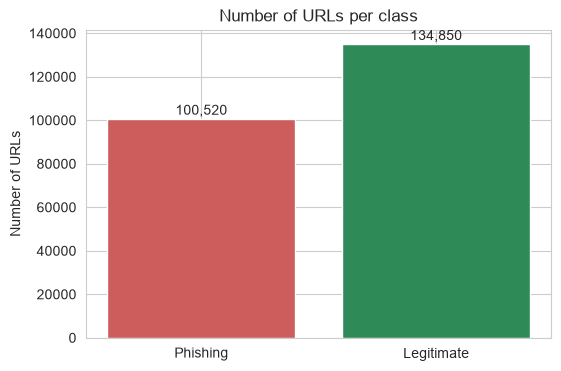

In [15]:
counts = df["label"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(CLASS_NAMES, counts.values, color=["indianred", "seagreen"])
for position, value in enumerate(counts.values):
    plt.text(position, value + 2000, f"{value:,}", ha="center")
plt.title("Number of URLs per class")
plt.ylabel("Number of URLs")
plt.show()

The two bars are close in height. A model that always answers "legitimate" reaches
57 percent accuracy, so 57 percent is the base line to beat.

## 6.2 Length of the URL

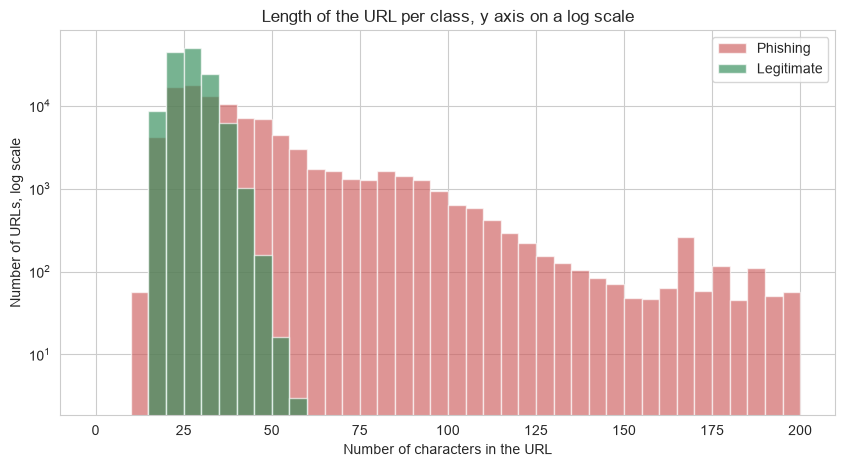

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,100520.0,45.70,61.25,13.0,26.0,34.0,48.0,6097.0
1,134850.0,26.23,4.82,15.0,23.0,26.0,29.0,57.0


In [16]:
bins = np.arange(0, 205, 5)

plt.figure(figsize=(10, 5))
plt.hist(df.loc[df["label"] == 0, "URLLength"], bins=bins, log=True,
         color="indianred", alpha=0.65, label="Phishing")
plt.hist(df.loc[df["label"] == 1, "URLLength"], bins=bins, log=True,
         color="seagreen", alpha=0.65, label="Legitimate")
plt.title("Length of the URL per class, y axis on a log scale")
plt.xlabel("Number of characters in the URL")
plt.ylabel("Number of URLs, log scale")
plt.legend()
plt.show()

df.groupby("label")["URLLength"].describe().round(2)

Legitimate URLs are short. The median is 26 characters and the longest legitimate URL
has 57 characters.

Phishing URLs are longer and spread out. The median is 34 characters and the longest is
6097. A phishing URL carries extra folders, long keywords and parameters. It copies the
wording of the brand that it imitates.

The y axis uses a log scale because the long tail holds very few rows.

## 6.3 Flags on the page and in the URL

These four columns hold 0 or 1, so a bar chart of the rate per class is the right form.

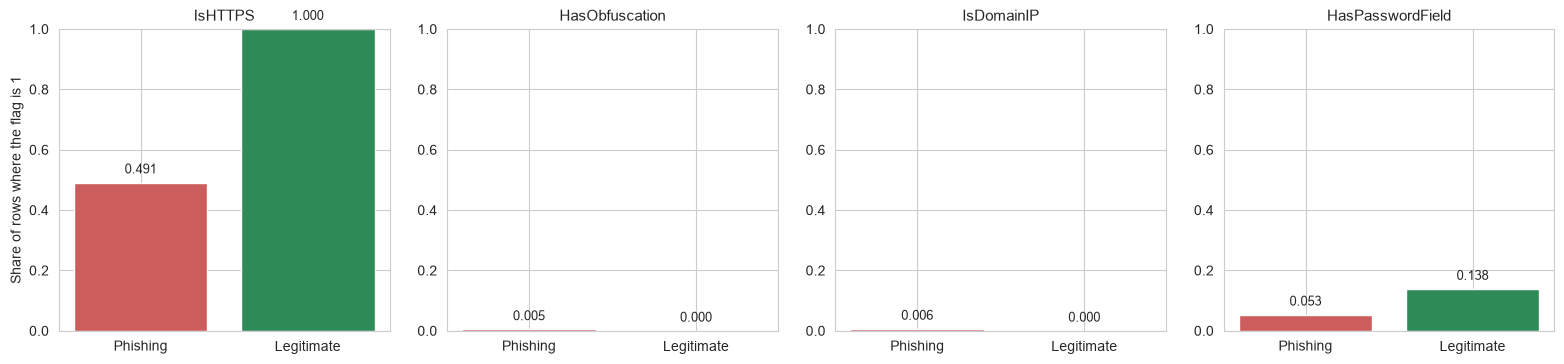

In [17]:
flag_columns = ["IsHTTPS", "HasObfuscation", "IsDomainIP", "HasPasswordField"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].set_ylabel("Share of rows where the flag is 1")

for axis, column in zip(axes, flag_columns):
    rates = df.groupby("label")[column].mean()
    axis.bar(CLASS_NAMES, rates.values, color=["indianred", "seagreen"])
    axis.set_title(column, fontsize=11)
    axis.set_ylim(0, 1)
    for position, value in enumerate(rates.values):
        axis.text(position, value + 0.03, f"{value:.3f}", ha="center", fontsize=9)
plt.tight_layout(pad=2)
plt.show()

Three results are worth a sentence each.

`IsHTTPS` gives a signal in one direction only. Every legitimate site has it, and half of
the phishing sites have it. A missing padlock is a warning sign. A padlock on its own
proves nothing, because a certificate costs nothing.

`HasPasswordField` is more common on legitimate sites, 0.138 against 0.053. Many phishing
pages send the password to another server, so the captured HTML holds a form but no
password box.

`HasObfuscation` and `IsDomainIP` are rare. They occur on 0.005 and 0.006 of the phishing
rows, and on no legitimate row. The bars for these two columns are almost flat, so read the
numbers above them and not the height. When one of them appears, the page is almost always
phishing.

## 6.4 Relation between each feature and the label

The number below is the Pearson correlation between one feature and the label. The label
holds 0 or 1. A positive value means that high values of the feature go with legitimate
sites.

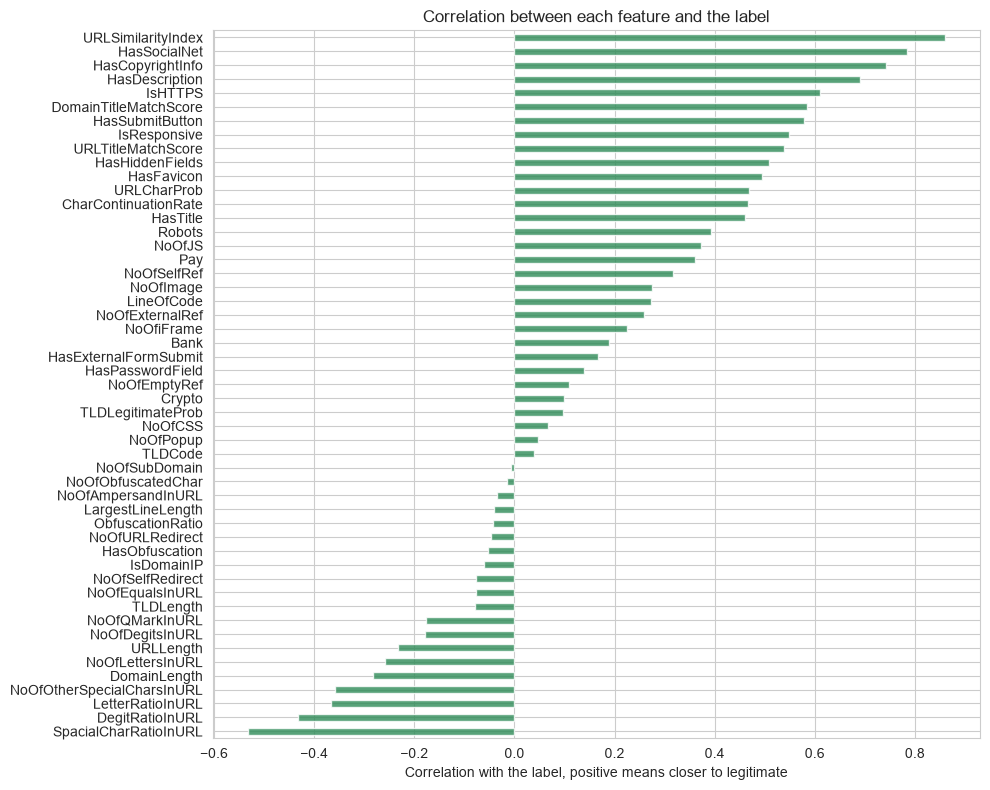

SpacialCharRatioInURL        -0.533
DegitRatioInURL              -0.432
LetterRatioInURL             -0.367
NoOfOtherSpecialCharsInURL   -0.358
DomainLength                 -0.283
NoOfLettersInURL             -0.258
URLLength                    -0.233
NoOfDegitsInURL              -0.178
NoOfQMarkInURL               -0.176
TLDLength                    -0.079
NoOfEqualsInURL              -0.077
NoOfSelfRedirect             -0.077
IsDomainIP                   -0.060
HasObfuscation               -0.053
NoOfURLRedirect              -0.046
ObfuscationRatio             -0.042
LargestLineLength            -0.041
NoOfAmpersandInURL           -0.035
NoOfObfuscatedChar           -0.015
NoOfSubDomain                -0.006
TLDCode                       0.039
NoOfPopup                     0.047
NoOfCSS                       0.068
TLDLegitimateProb             0.097
Crypto                        0.100
NoOfEmptyRef                  0.109
HasPasswordField              0.139
HasExternalFormSubmit       

In [18]:
feature_columns = [column for column in df.columns if column != "label"]

correlation_with_label = df[feature_columns].corrwith(df["label"]).sort_values()

plt.figure(figsize=(10, 8))
correlation_with_label.plot(kind="barh", color="seagreen", alpha=0.8)
plt.title("Correlation between each feature and the label")
plt.xlabel("Correlation with the label, positive means closer to legitimate")
plt.tight_layout()
plt.show()

correlation_with_label.round(3)

The strongest positive values belong to features of the page: `HasSocialNet`,
`HasCopyrightInfo`, `HasDescription` and `IsHTTPS`. A real company site has social links,
a copyright line and a description. A throwaway page usually has none.

The largest negative values belong to the text of the URL: `SpacialCharRatioInURL`,
`DegitRatioInURL` and `URLLength`. Phishing URLs hold more symbols, more digits and more
characters.

The two groups give different information, which is why both stay in the model.

# Step 7: Feature selection and evaluation (R2)

The file has 235,370 rows. A full run with ten models and BERT takes hours on a laptop. A stratified sample of 24,000 rows is therefore used, with the same number of rows
from each class.

Stratified means that the class ratio in the sample is fixed in advance. 24,000 rows is
large enough to keep the standard error of an accuracy estimate under one percentage point.

The URLs are taken from the sample before the index is reset. The index links each row to
its URL, so a reset in the wrong place attaches the wrong URL to a row.

In [19]:
half = SAMPLE_SIZE // 2

phishing_rows = df[df["label"] == 0].sample(n=half, random_state=RANDOM_STATE)
legitimate_rows = df[df["label"] == 1].sample(n=half, random_state=RANDOM_STATE)

sample_df = pd.concat([phishing_rows, legitimate_rows])
sample_df = sample_df.sample(frac=1, random_state=RANDOM_STATE)

urls_sample = url_table.loc[sample_df.index].reset_index(drop=True)
data = sample_df.reset_index(drop=True)

print("Sample shape:", data.shape)
print(data["label"].value_counts())

Sample shape: (24000, 52)
label
0    12000
1    12000
Name: count, dtype: int64


## 7.1 Three methods to rank the features

One method alone is not reliable, so three methods are used and their ranks are averaged.
A feature that all three methods rank high is unlikely to be there by chance.

1. Correlation with the label. It finds a straight line relation only.
2. Mutual information. It measures how much a feature reduces doubt about the label, and
   it also finds a curved relation.
3. Importance from a random forest. It measures how much a feature reduces impurity across
   200 trees, and it also finds relations between pairs of features.

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif

feature_columns = [column for column in data.columns if column != "label"]

mutual_information = mutual_info_classif(
    data[feature_columns], data["label"], random_state=RANDOM_STATE
)

forest_for_ranking = RandomForestClassifier(
    n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
)
forest_for_ranking.fit(data[feature_columns], data["label"])

print("Rankings calculated for", len(feature_columns), "features")

Rankings calculated for 51 features


In [21]:
correlation_scores = data[feature_columns].corrwith(data["label"])
correlation_scores = correlation_scores.reindex(feature_columns).abs()

importance_table = pd.DataFrame({
    "Feature": feature_columns,
    "Correlation": correlation_scores.values,
    "MutualInformation": mutual_information,
    "RandomForest": forest_for_ranking.feature_importances_,
})

for column in ["Correlation", "MutualInformation", "RandomForest"]:
    importance_table[column + "Rank"] = importance_table[column].rank(ascending=False)

importance_table["AverageRank"] = importance_table[
    ["CorrelationRank", "MutualInformationRank", "RandomForestRank"]
].mean(axis=1)

importance_table = importance_table.sort_values("AverageRank").reset_index(drop=True)
importance_table.head(20).round(4)

,Feature,Correlation,MutualInformation,RandomForest,CorrelationRank,MutualInformationRank,RandomForestRank,AverageRank
0,URLSimilarityIndex,0.8446,0.6687,0.1780,1.0,1.0,1.0,1.0000
1,HasSocialNet,0.7974,0.3958,0.0510,2.0,9.0,7.0,6.0000
2,NoOfJS,0.5762,0.5068,0.0910,8.0,6.0,6.0,6.6667
3,HasCopyrightInfo,0.7622,0.3393,0.0468,3.0,11.0,8.0,7.3333
4,HasDescription,0.7136,0.2975,0.0228,4.0,12.0,11.0,9.0000
5,NoOfCSS,0.4694,0.4530,0.0372,14.0,8.0,9.0,10.3333
6,NoOfExternalRef,0.2424,0.5681,0.1280,28.0,3.0,2.0,11.0000
7,IsHTTPS,0.5893,0.2223,0.0147,7.0,14.0,13.0,11.3333
8,LineOfCode,0.2317,0.6044,0.1091,29.0,2.0,3.0,11.3333
9,NoOfImage,0.2764,0.5508,0.0949,25.0,4.0,5.0,11.3333


## 7.2 The features used by the models

The top twenty features are taken from that table. Three of them are the similarity columns
from Step 1, so they are removed here.

A column that compares the URL with the official URL of the brand is close to a copy of the
label. A model that leans on it does not learn to recognise phishing. It only makes sure
that the URL matches an official one. The seventeen remaining features carry the real signal.

In [22]:
top_twenty = importance_table.head(20)["Feature"].tolist()
SELECTED_FEATURES = [feature for feature in top_twenty if feature not in SIMILARITY_FEATURES]

print("Top twenty features        :", len(top_twenty))
print("Features used by the models:", len(SELECTED_FEATURES))
for position, feature in enumerate(SELECTED_FEATURES, start=1):
    print(" ", position, feature)

Top twenty features        : 20
Features used by the models: 17
  1 HasSocialNet
  2 NoOfJS
  3 HasCopyrightInfo
  4 HasDescription
  5 NoOfCSS
  6 NoOfExternalRef
  7 IsHTTPS
  8 LineOfCode
  9 NoOfImage
  10 NoOfSelfRef
  11 HasSubmitButton
  12 NoOfOtherSpecialCharsInURL
  13 SpacialCharRatioInURL
  14 IsResponsive
  15 LetterRatioInURL
  16 NoOfiFrame
  17 DegitRatioInURL


## 7.3 The ranking of those features

This graph shows the seventeen features in the order of their random forest importance, so
that it matches the input of the models exactly.

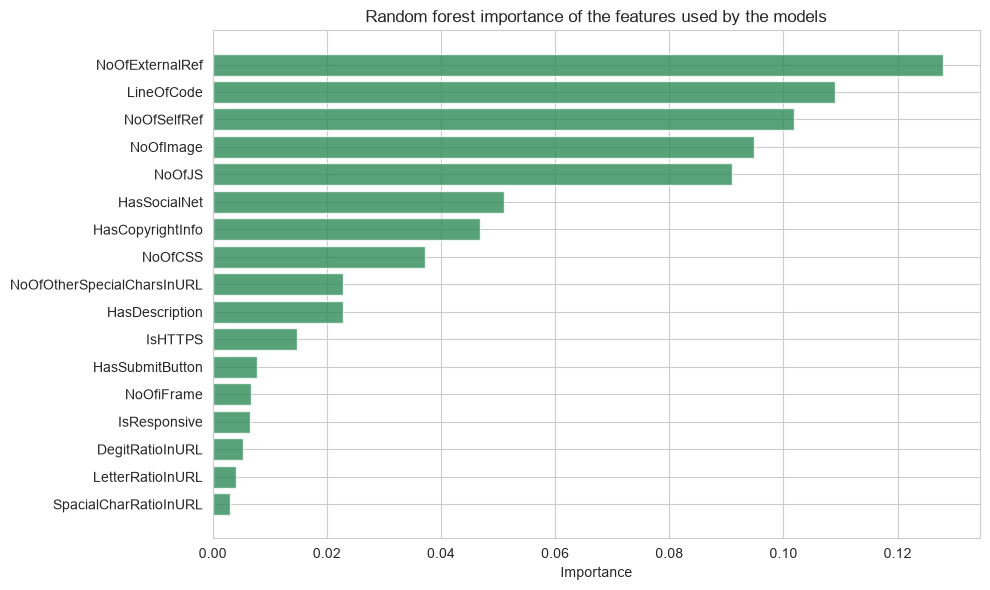

In [23]:
plot_table = importance_table[importance_table["Feature"].isin(SELECTED_FEATURES)]
plot_table = plot_table.sort_values("RandomForest")

plt.figure(figsize=(10, 6))
plt.barh(plot_table["Feature"], plot_table["RandomForest"], color="seagreen", alpha=0.8)
plt.title("Random forest importance of the features used by the models")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

The order answers RQ2. Features of the page come first: `LineOfCode`, `NoOfExternalRef`,
`NoOfSelfRef`, `NoOfImage` and `NoOfCSS`. A real site links to its own pictures and
scripts. A fake page borrows them from other servers.

Features of the text of the URL come later. `URLLength` and the ratio features do make the
list, but none reaches the top ten. Length alone is a weaker signal than common advice
suggests.

# Step 8: Split and scaling (R2)

The data is split 70 to 30. The split is stratified, so the class ratio is the same in both
parts. The test set is used only for the final scores. It never helps to choose anything,
which keeps the numbers honest.

Scaling subtracts the mean and divides by the standard deviation. Logistic regression,
the perceptron, k nearest neighbours and the neural networks need it. Trees do not need
it, and it does them no harm.

The scaler is fitted on the training rows only. A scaler fitted on all rows passes
information about the test set into training.

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train_frame, X_test_frame, y_train, y_test = train_test_split(
    data[SELECTED_FEATURES], data["label"],
    test_size=TEST_SIZE, stratify=data["label"], random_state=RANDOM_STATE
)

# the URL text for the same rows, for the text models in Step 12
urls_train = urls_sample.loc[X_train_frame.index].reset_index(drop=True)
urls_test = urls_sample.loc[X_test_frame.index].reset_index(drop=True)

print("Training rows:", len(X_train_frame))
print("Test rows    :", len(X_test_frame))

Training rows: 16800
Test rows    : 7200


In [25]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_frame)
X_test = scaler.transform(X_test_frame)

print("Training matrix:", X_train.shape)
print("Test matrix    :", X_test.shape)

Training matrix: (16800, 17)
Test matrix    : (7200, 17)


# Step 9: Clustering, K-Means and EM (R2)

This step is unsupervised. The model never sees the label. The label is used afterwards as
a yardstick, to ask whether the groups that the algorithm found match the two classes.

Two algorithms from the syllabus are compared.

- K-Means puts each row into the group of its nearest centre. It assumes round groups of
  similar size.
- A Gaussian mixture uses the EM algorithm. It fits two Gaussian distributions and gives
  each row a probability for each one. The groups can be oval and of different sizes.

The data is first reduced to five principal components. Several features are near
duplicates, and the duplicated page counters otherwise dominate the distance.

In [26]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.mixture import GaussianMixture

pca = PCA(n_components=5, random_state=RANDOM_STATE)
X_cluster = pca.fit_transform(X_train)

print("Variance kept by the five components:", round(pca.explained_variance_ratio_.sum(), 3))

Variance kept by the five components: 0.622


The number of groups is not guessed. The sweep below runs k from 2 to 8 and records three
metrics.

- Inertia is the total squared distance from each row to its centre. It always falls as k
  grows, so the shape of the curve matters and the value alone does not.
- The silhouette score compares the distance to the own group with the distance to the next
  group. A high value is good. The range is minus one to one.
- The Calinski-Harabasz score is the ratio of the spread between groups to the spread
  inside groups. A high value is good.

In [27]:
cluster_results = []

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    cluster_labels = kmeans.fit_predict(X_cluster)

    cluster_results.append({
        "k": k,
        "Inertia": kmeans.inertia_,
        "Silhouette": silhouette_score(X_cluster, cluster_labels),
        "CalinskiHarabasz": calinski_harabasz_score(X_cluster, cluster_labels),
    })

cluster_results = pd.DataFrame(cluster_results)
cluster_results.round(3)

,k,Inertia,Silhouette,CalinskiHarabasz
0,2,104570.961,0.466,11750.073
1,3,90345.764,0.413,8122.034
2,4,76485.803,0.421,7410.034
3,5,67462.926,0.358,6862.035
4,6,58831.158,0.379,6787.508
5,7,50811.718,0.375,6990.299
6,8,46516.562,0.332,6766.029


The three metrics agree on k = 2. Inertia drops fastest up to that point, then flattens.
The silhouette score is highest at k = 2 and lower at every larger k. The
Calinski-Harabasz score falls from k = 2 onwards.

Two groups is also the value that can be compared with the two real classes, so the final
models use two.

In [28]:
kmeans_final = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans_final.fit_predict(X_cluster)

gmm_final = GaussianMixture(
    n_components=2,
    covariance_type="diag",
    init_params="kmeans",
    n_init=5,
    random_state=RANDOM_STATE,
)
gmm_labels = gmm_final.fit_predict(X_cluster)

clustering_comparison = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "AdjustedRandIndex": adjusted_rand_score(y_train, kmeans_labels),
        "NormalisedMutualInfo": normalized_mutual_info_score(y_train, kmeans_labels),
        "Silhouette": silhouette_score(X_cluster, kmeans_labels),
        "Group sizes": str(np.bincount(kmeans_labels)),
    },
    {
        "Algorithm": "Gaussian mixture with EM",
        "AdjustedRandIndex": adjusted_rand_score(y_train, gmm_labels),
        "NormalisedMutualInfo": normalized_mutual_info_score(y_train, gmm_labels),
        "Silhouette": silhouette_score(X_cluster, gmm_labels),
        "Group sizes": str(np.bincount(gmm_labels)),
    },
])

clustering_comparison.round(3)

,Algorithm,AdjustedRandIndex,NormalisedMutualInfo,Silhouette,Group sizes
0,K-Means,0.881,0.815,0.466,[8024 8776]
1,Gaussian mixture with EM,0.915,0.855,0.458,[8605 8195]


Three metrics are used here, and each answers a different question.

- The adjusted Rand index measures the agreement between the groups and the true labels.
  It corrects for agreement that happens by chance. The value 1 is a perfect match and
  0 is the level of chance.
- Normalised mutual information measures how much the group of a row tells about its label.
  The range is 0 to 1.
- The silhouette score measures the quality of the groups without the labels.

The two algorithms agree closely, and both recover the two classes far better than
hypothesis H3 expected. The reason is in the next table.

In [29]:
pd.crosstab(kmeans_labels, y_train.values, rownames=["Group"], colnames=["True label"])

True label,0,1
Group,,
0,69,7955
1,8331,445


Each group holds almost one whole class. The separation between phishing and legitimate is
the largest direction of variation in this sample, so an algorithm that only maximises
variance between groups finds it almost without effort.

A high score here does not mean that clustering is a phishing detector. It means that this
sample is clean enough for two separate regions to exist. On live traffic the regions
overlap, and the model still does not know which group holds the danger. Clustering
describes groups. Only a supervised model can name them.

The graph below shows the two groups next to the true classes.

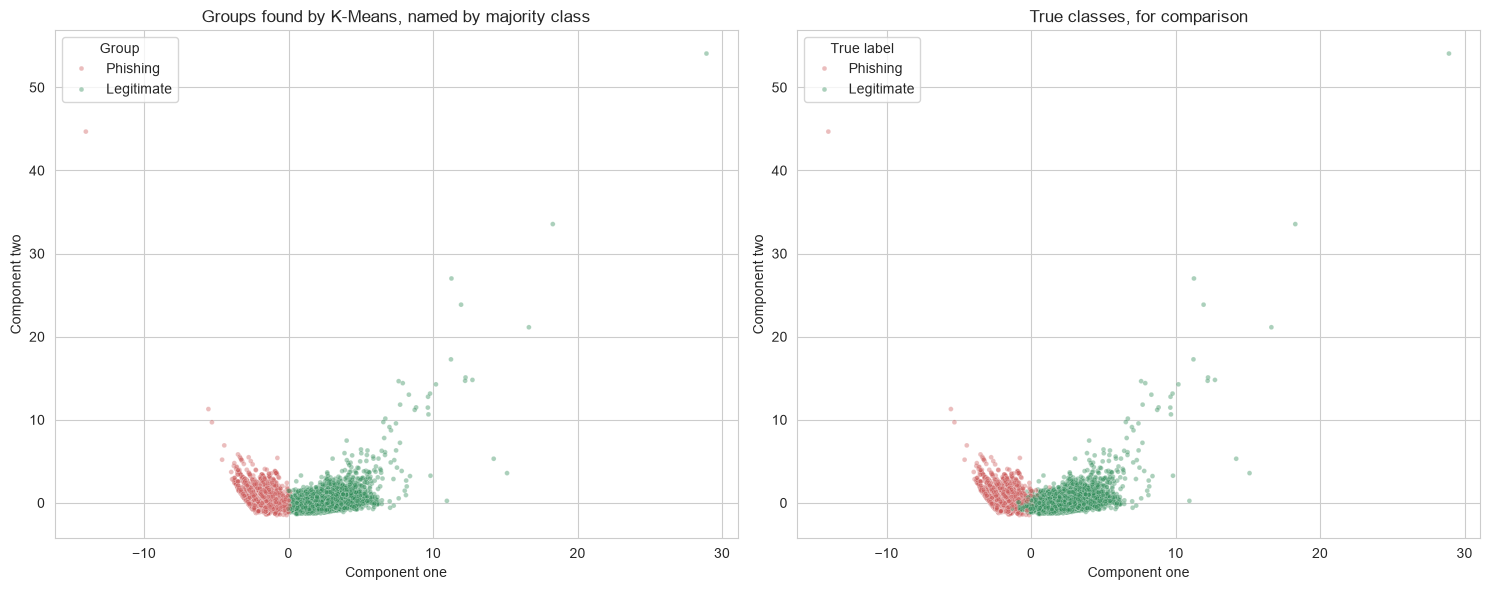

In [30]:
# each group takes the name of the class that holds most of its rows, so that both
# panels below use one colour for one meaning
group_counts = pd.crosstab(kmeans_labels, y_train.values)
group_names = {group: CLASS_NAMES[row.idxmax()] for group, row in group_counts.iterrows()}

group_plot = pd.DataFrame({
    "Component one": X_cluster[:, 0],
    "Component two": X_cluster[:, 1],
    "Group": [group_names[group] for group in kmeans_labels],
    "True label": [CLASS_NAMES[value] for value in y_train.values],
})

colours = {"Phishing": "indianred", "Legitimate": "seagreen"}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=group_plot, x="Component one", y="Component two", hue="Group",
                hue_order=["Phishing", "Legitimate"], palette=colours,
                alpha=0.4, s=12, ax=axes[0])
axes[0].set_title("Groups found by K-Means, named by majority class")

sns.scatterplot(data=group_plot, x="Component one", y="Component two", hue="True label",
                hue_order=["Phishing", "Legitimate"], palette=colours,
                alpha=0.4, s=12, ax=axes[1])
axes[1].set_title("True classes, for comparison")

plt.tight_layout()
plt.show()

Each group is named after the class that holds most of its rows, so one colour means one
thing in both panels. The two panels look alike, which is the point of the two tables
above. The groups that K-Means found without the labels sit in the same two regions as the
real classes.

# Step 10: Classical models (R3)

Seven classical algorithms are trained on the same rows.

| Model | Family | Reason for its place here |
|---|---|---|
| Gaussian Naive Bayes | generative, probabilistic | The naive Bayes from the syllabus. Fast, and it assumes that the features are independent. |
| Logistic Regression | discriminative, linear | The reference linear model. The coefficients can be read. |
| Perceptron | discriminative, linear | The simplest neural unit from the syllabus. Shows the cost of a hard boundary. |
| k Nearest Neighbours | instance based | Assumes no shape for the boundary. Shows how far plain similarity gets us. |
| Decision Tree | discriminative, rules | The rules can be read. Step 11 covers it in detail. |
| Random Forest | ensemble, bagging | Many trees on bootstrap samples. The average cuts the variance of one tree. |
| Histogram Gradient Boosting | ensemble, boosting | Trees built in a row, and each tree corrects the errors of the last. |

Five metrics are reported for each model, because no single metric is enough for a
security tool.

- Accuracy is the share of correct answers. It hides a bad result when the classes are
  uneven.
- Precision answers one question. Of the rows flagged as phishing, how many were phishing?
  A low value wastes analyst time on false alarms.
- Recall answers a second question. Of the real phishing rows, how many did we catch? A low
  value leaves users exposed.
- F1 is the harmonic mean of precision and recall. It is useful when the two must be traded.
- ROC-AUC measures how well a model ranks a random phishing row above a random legitimate
  row, at any cut off. A deployed system picks its cut off from a budget, not from 0.5.

In [31]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier


def get_probabilities(model, features):
    # Some models give a raw score only, the perceptron for example. The score is
    # pushed through a logistic function to make a probability.
    if hasattr(model, "predict_proba"):
        return model.predict_proba(features)[:, 1]
    scores = model.decision_function(features)
    return 1.0 / (1.0 + np.exp(-scores))

In [32]:
models = {
    "Gaussian Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Perceptron": Perceptron(max_iter=1000, random_state=RANDOM_STATE),
    "k Nearest Neighbours": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Histogram Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

rows = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = get_probabilities(model, X_test)

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
    })
    trained_models[name] = model
    print("Finished:", name)

classical_results = pd.DataFrame(rows).set_index("Model").sort_values("F1", ascending=False)
classical_results.round(4)

Finished: Gaussian Naive Bayes
Finished: Logistic Regression
Finished: Perceptron
Finished: k Nearest Neighbours
Finished: Decision Tree


Finished: Random Forest


Finished: Histogram Gradient Boosting


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Histogram Gradient Boosting,0.9986,0.9989,0.9983,0.9986,1.0000
Random Forest,0.9986,0.9992,0.9981,0.9986,1.0000
Logistic Regression,0.9976,0.9978,0.9975,0.9976,1.0000
Perceptron,0.9958,0.9953,0.9964,0.9958,0.9999
k Nearest Neighbours,0.9956,0.9947,0.9964,0.9956,0.9987
Decision Tree,0.9954,0.9947,0.9961,0.9954,0.9954
Gaussian Naive Bayes,0.9932,0.9901,0.9964,0.9932,0.9974


Hypothesis H1 holds. Every model passes 99 percent accuracy, and the two ensembles reach
the top.

Histogram gradient boosting and the random forest lead. Gaussian naive Bayes comes last
because its assumption of independent features is false here. The page counters repeat each
other, as Step 6 showed. Step 12 answers the separate question about neural networks.

The table states the result better than a graph can. Every model sits between 0.993 and
0.999, so a bar chart shows seven identical bars.

# Step 11: Decision trees in practice (R3)

The brief asks for a discussion of how decision trees apply to this dataset and topic.

## 11.1 The rules that a tree learns

A shallow tree of depth three is fitted, so that every rule fits on one line. A deep tree
is more accurate and produces hundreds of conditions, which no reviewer can read.

In [33]:
from sklearn.tree import export_text, plot_tree

shallow_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
shallow_tree.fit(X_train, y_train)

print("Accuracy of the depth three tree:", round(shallow_tree.score(X_test, y_test), 4))
print()
print(export_text(shallow_tree, feature_names=SELECTED_FEATURES, max_depth=3))

Accuracy of the depth three tree: 0.9879

|--- NoOfExternalRef <= -0.20
|   |--- NoOfSelfRef <= -0.34
|   |   |--- NoOfImage <= -0.04
|   |   |   |--- class: 0
|   |   |--- NoOfImage >  -0.04
|   |   |   |--- class: 1
|   |--- NoOfSelfRef >  -0.34
|   |   |--- LineOfCode <= -0.21
|   |   |   |--- class: 0
|   |   |--- LineOfCode >  -0.21
|   |   |   |--- class: 1
|--- NoOfExternalRef >  -0.20
|   |--- NoOfOtherSpecialCharsInURL <= 0.21
|   |   |--- LineOfCode <= -0.21
|   |   |   |--- class: 0
|   |   |--- LineOfCode >  -0.21
|   |   |   |--- class: 1
|   |--- NoOfOtherSpecialCharsInURL >  0.21
|   |   |--- NoOfSelfRef <= -0.19
|   |   |   |--- class: 0
|   |   |--- NoOfSelfRef >  -0.19
|   |   |   |--- class: 1



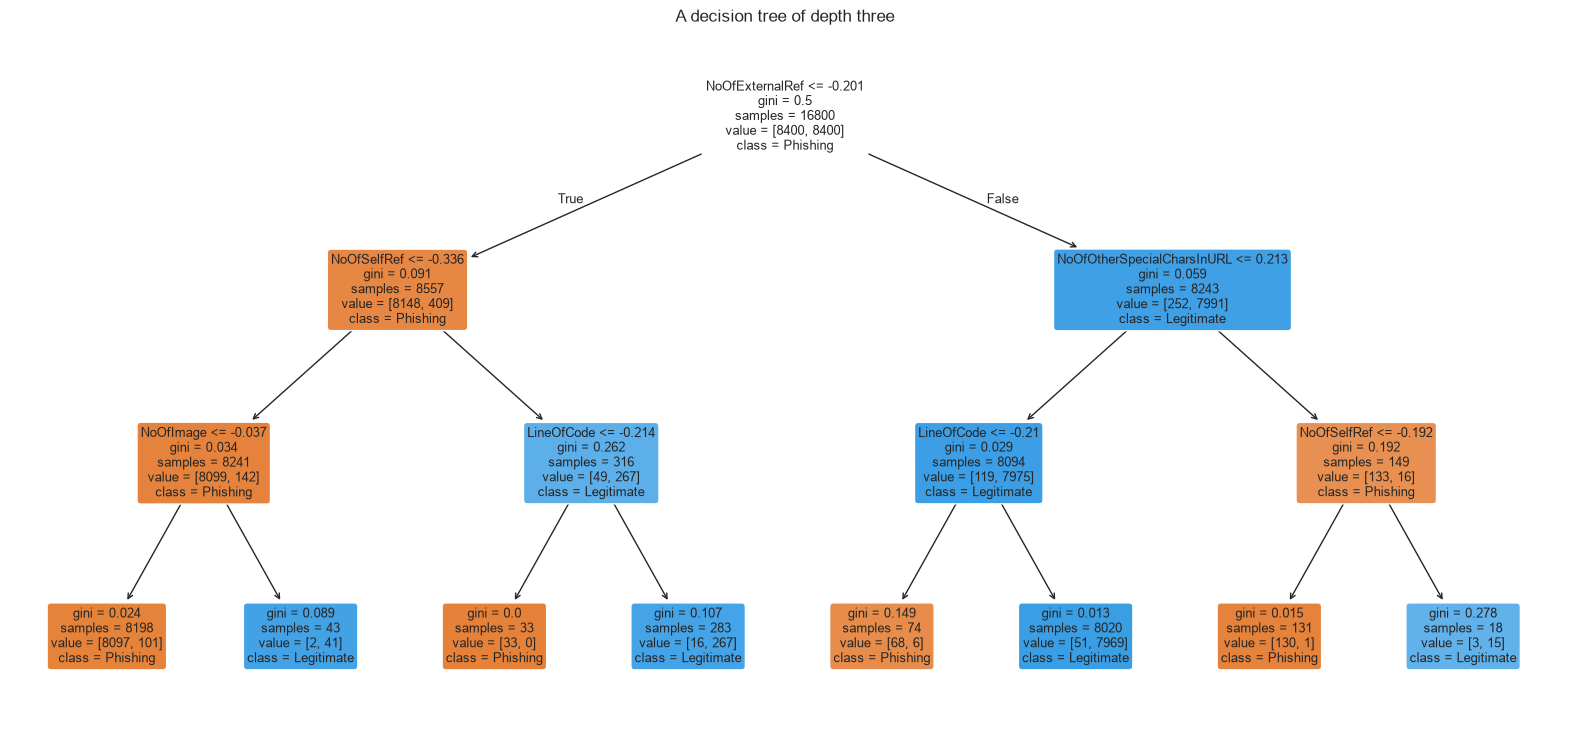

In [34]:
plt.figure(figsize=(20, 9))
plot_tree(shallow_tree, feature_names=SELECTED_FEATURES, class_names=CLASS_NAMES,
          filled=True, rounded=True, fontsize=9, max_depth=3)
plt.title("A decision tree of depth three")
plt.show()

Three conditions are enough to reach almost the full accuracy of the ensembles. Each
condition is a statement that an analyst can read: how much code the page holds, how many
pictures it loads from its own server, and how many symbols its URL carries.

That readable path is the value of a decision tree in security work. When the system says
"this URL was blocked", the analyst can show the exact conditions that caused the block.

## 11.2 Where decision trees help in this topic

1. Explainable blocking. A security team must justify a block to a customer who disagrees.
   A tree path is that justification in plain words.
2. A fast first model. The tree above trains in less than one second. It shows whether a
   problem is hard before anyone spends a month on a neural network.
3. Rules inside network equipment. A tree path becomes a short list of if statements. Such
   a list runs inside a mail gateway or a browser extension, where a neural network cannot go.
4. Numbers for a policy. A split such as "the page holds fewer than N lines of code" is a
   number that a product team can argue about. A network weight is not.
5. A test of other models. If a shallow tree nearly matches a random forest, the relation is
   simple and the forest adds cost without benefit. The gap here is small.
6. Mixed data without scaling. A tree needs no scaling. It handles a mix of flags and counts,
   which is exactly this dataset.

## 11.3 Where decision trees fail

A single tree with no depth limit memorises the training rows. The table below shows the
training accuracy and the test accuracy for the three tree models.

In [35]:
tree_check = pd.DataFrame([
    {
        "Model": "Decision Tree, no depth limit",
        "Training accuracy": trained_models["Decision Tree"].score(X_train, y_train),
        "Test accuracy": trained_models["Decision Tree"].score(X_test, y_test),
    },
    {
        "Model": "Decision Tree, depth three",
        "Training accuracy": shallow_tree.score(X_train, y_train),
        "Test accuracy": shallow_tree.score(X_test, y_test),
    },
    {
        "Model": "Random Forest, 300 trees",
        "Training accuracy": trained_models["Random Forest"].score(X_train, y_train),
        "Test accuracy": trained_models["Random Forest"].score(X_test, y_test),
    },
])

tree_check.round(4)

,Model,Training accuracy,Test accuracy
0,"Decision Tree, no depth limit",1.0000,0.9954
1,"Decision Tree, depth three",0.9893,0.9879
2,"Random Forest, 300 trees",1.0000,0.9986


The tree with no depth limit reaches one on the training rows. That is memorisation, and it
is the reason for the depth limit and for the ensembles. A forest averages many trees of
high variance, gives up some training accuracy and keeps more test accuracy.

A tree has a second limit. It cannot express a smooth rule such as "length matters more
when the URL has many sub domains" without many splits. The ensembles reduce this problem
and the neural networks in Step 12 approach it in a different way.

# Step 12: Neural networks (R4)

Three networks are trained, and each one answers a different question.

| Network | Input | Question |
|---|---|---|
| Multi layer perceptron | the seventeen numeric features | Does a non linear network beat the classical models on the same input? |
| Character CNN | the URL as a string of characters | Can a network learn the shape of a URL from nothing? |
| BERT with a small head | the URL encoded by a pretrained model | Does a language model add information that the features do not hold? |

A CNN over images is not included, because this topic has no image data. The convolutional
idea is applied to the one dimensional string of characters instead, which is the natural
form here.

## 12.1 The multi layer perceptron

A perceptron of several layers stacks fully connected layers and puts a non linear function
between them. Two small hidden layers are usually enough for a table of numbers.

Two settings are chosen on purpose. `alpha` is the L2 penalty, and it is the main defence
against overfitting on 16,800 rows. `early_stopping` stops the training when the validation
loss stops improving.

In [36]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=0.0001,
    learning_rate_init=0.001,
    batch_size=256,
    max_iter=200,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=RANDOM_STATE,
)

mlp_model.fit(X_train, y_train)
print("Epochs before early stopping:", mlp_model.n_iter_)

Epochs before early stopping: 21


In [37]:
mlp_predictions = mlp_model.predict(X_test)
mlp_probabilities = mlp_model.predict_proba(X_test)[:, 1]

mlp_result = {
    "Model": "Multi layer perceptron",
    "Accuracy": accuracy_score(y_test, mlp_predictions),
    "Precision": precision_score(y_test, mlp_predictions),
    "Recall": recall_score(y_test, mlp_predictions),
    "F1": f1_score(y_test, mlp_predictions),
    "ROC_AUC": roc_auc_score(y_test, mlp_probabilities),
}

pd.DataFrame([mlp_result]).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Multi layer perceptron,0.9976,0.9983,0.9969,0.9976,1.0


The perceptron lands level with logistic regression and below the two ensembles. Hypothesis
H4 holds. A network does not win here, because the decision is mostly a set of thresholds
and a tree models a threshold directly.

## 12.2 BERT on the text of the URL

BERT is a language model built from transformers. It reads text and returns one vector for
each word piece. Each vector carries the meaning of that piece inside its context.

The model here is `google/bert_uncased_L-2_H-128_A-2`, the small BERT installed on this
machine. It has 2 layers and 128 hidden units, against 12 layers and 768 units in the full
model. It is small enough to encode 24,000 URLs on a laptop processor in a few minutes.

The URL is turned into numbers in three steps. The text is cut into word pieces. The model
gives one 128 number vector for each piece. The vectors are averaged, and padding is
ignored. This is called mean pooling.

The weights of BERT stay fixed. Only the small classifier on top is trained. 16,800 rows
are too few to fine tune a language model without damage to what it already knows.

In [38]:
import torch
from transformers import AutoModel, AutoTokenizer

BERT_MODEL_NAME = "google/bert_uncased_L-2_H-128_A-2"
MAX_TOKEN_LENGTH = 48

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
bert_model = AutoModel.from_pretrained(BERT_MODEL_NAME)
bert_model.eval()

print("Model loaded:", BERT_MODEL_NAME)
print("Hidden size :", bert_model.config.hidden_size)

W1116 01:55:32.350000 99914 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Model loaded: google/bert_uncased_L-2_H-128_A-2
Hidden size : 128


In [39]:
def make_bert_embeddings(url_list, batch_size=128):
    vectors = []

    for start in range(0, len(url_list), batch_size):
        batch = [str(url) for url in url_list[start:start + batch_size]]

        tokens = bert_tokenizer(
            batch, padding=True, truncation=True,
            max_length=MAX_TOKEN_LENGTH, return_tensors="pt",
        )

        with torch.no_grad():
            outputs = bert_model(**tokens)

        mask = tokens["attention_mask"].unsqueeze(-1).float()
        summed = (outputs.last_hidden_state * mask).sum(dim=1)
        vectors.append((summed / mask.sum(dim=1)).numpy())

    return np.vstack(vectors)

In [40]:
X_train_bert = make_bert_embeddings(urls_train.tolist())
X_test_bert = make_bert_embeddings(urls_test.tolist())

print("Training embeddings:", X_train_bert.shape)
print("Test embeddings    :", X_test_bert.shape)

Training embeddings: (16800, 128)
Test embeddings    : (7200, 128)


In [41]:
bert_scaler = StandardScaler()
X_train_bert = bert_scaler.fit_transform(X_train_bert)
X_test_bert = bert_scaler.transform(X_test_bert)

bert_classifier = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=0.0001,
    learning_rate_init=0.001,
    batch_size=256,
    max_iter=200,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=RANDOM_STATE,
)

bert_classifier.fit(X_train_bert, y_train)

bert_predictions = bert_classifier.predict(X_test_bert)
bert_probabilities = bert_classifier.predict_proba(X_test_bert)[:, 1]

bert_result = {
    "Model": "BERT with a small head",
    "Accuracy": accuracy_score(y_test, bert_predictions),
    "Precision": precision_score(y_test, bert_predictions),
    "Recall": recall_score(y_test, bert_predictions),
    "F1": f1_score(y_test, bert_predictions),
    "ROC_AUC": roc_auc_score(y_test, bert_probabilities),
}

pd.DataFrame([bert_result]).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
BERT with a small head,0.9626,0.953,0.9733,0.963,0.9911


## 12.3 A character CNN on the text of the URL

A convolutional network slides a small filter over a sequence. Over images the filter finds
edges. Over text the same filter finds short shapes such as `://`, `login` or a run of
digits.

The network has four parts.

1. An embedding layer turns each character into a small vector.
2. A convolution slides a filter of width five over the characters.
3. A max pooling step keeps the strongest answer of each filter anywhere in the URL. The
   model therefore does not care where in the URL a pattern appears.
4. A last layer gives one number, the probability that the row is legitimate.

URLs are cut to 80 characters. Long URLs repeat themselves after that point.

In [42]:
import torch.nn as nn

torch.manual_seed(RANDOM_STATE)

MAX_CHARS = 80
VOCAB_SIZE = 128   # one slot for each standard ASCII code


def encode_urls(url_list):
    matrix = np.zeros((len(url_list), MAX_CHARS), dtype=np.int64)
    for row, url in enumerate(url_list):
        for column, character in enumerate(str(url)[:MAX_CHARS]):
            code = ord(character)
            if code < VOCAB_SIZE:
                matrix[row, column] = code
    return matrix


X_train_chars = encode_urls(urls_train.tolist())
X_test_chars = encode_urls(urls_test.tolist())

print("Character matrix for training:", X_train_chars.shape)

Character matrix for training: (16800, 80)


In [43]:
class UrlCharacterCNN(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, embed_dim=32, filters=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.convolution = nn.Conv1d(embed_dim, filters, kernel_size=5, padding=2)
        self.dropout = nn.Dropout(0.3)
        self.output = nn.Linear(filters, 1)

    def forward(self, characters):
        vectors = self.embedding(characters).transpose(1, 2)
        activated = torch.relu(self.convolution(vectors))
        strongest = activated.max(dim=2).values
        return self.output(self.dropout(strongest)).squeeze(1)

In [44]:
cnn_model = UrlCharacterCNN()
loss_function = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

train_characters = torch.tensor(X_train_chars)
train_targets = torch.tensor(y_train.values.astype("float32"))
test_characters = torch.tensor(X_test_chars)

EPOCHS = 10
BATCH_SIZE = 256

for epoch in range(EPOCHS):
    cnn_model.train()
    order = torch.randperm(len(train_characters))

    running_loss = 0.0
    for start in range(0, len(train_characters), BATCH_SIZE):
        batch_index = order[start:start + BATCH_SIZE]

        optimizer.zero_grad()
        logits = cnn_model(train_characters[batch_index])
        loss = loss_function(logits, train_targets[batch_index])
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(batch_index)

    print("Epoch", epoch + 1, "training loss", round(running_loss / len(train_characters), 4))

Epoch 1 training loss 0.3103


Epoch 2 training loss 0.0479


Epoch 3 training loss 0.0295


Epoch 4 training loss 0.0239


Epoch 5 training loss 0.0213


Epoch 6 training loss 0.019


Epoch 7 training loss 0.0179


Epoch 8 training loss 0.0171


Epoch 9 training loss 0.0167


Epoch 10 training loss 0.015


In [45]:
cnn_model.eval()

with torch.no_grad():
    cnn_probabilities = torch.sigmoid(cnn_model(test_characters)).numpy()

cnn_predictions = (cnn_probabilities >= 0.5).astype(int)

cnn_result = {
    "Model": "Character CNN on the URL",
    "Accuracy": accuracy_score(y_test, cnn_predictions),
    "Precision": precision_score(y_test, cnn_predictions),
    "Recall": recall_score(y_test, cnn_predictions),
    "F1": f1_score(y_test, cnn_predictions),
    "ROC_AUC": roc_auc_score(y_test, cnn_probabilities),
}

pd.DataFrame([cnn_result]).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Character CNN on the URL,0.9967,0.9934,1.0,0.9967,0.9984


## 12.4 Which input gives the best result

The three networks and the classical models read different inputs. The table below puts
them together, and it answers RQ4.

In [46]:
pd.DataFrame([
    {**mlp_result, "Input": "seventeen numeric features"},
    {**cnn_result, "Input": "characters of the URL"},
    {**bert_result, "Input": "BERT vector of the URL"},
]).set_index("Model").round(4).sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,ROC_AUC,Input
Model,,,,,,
Multi layer perceptron,0.9976,0.9983,0.9969,0.9976,1.0000,seventeen numeric features
Character CNN on the URL,0.9967,0.9934,1.0000,0.9967,0.9984,characters of the URL
BERT with a small head,0.9626,0.9530,0.9733,0.9630,0.9911,BERT vector of the URL


Four results follow from this table. The first one compares the three networks with each
other. The last two look ahead to Step 13, where the classical models join the table.

The numeric features win. They are the only input that describes the page itself, and Step
7 showed that the page carries most of the signal.

The character CNN comes next. A network trained from nothing on the raw text beats a
pretrained language model on the same text.

BERT comes last. Its mean pooled vector compresses a whole URL into 128 numbers, and that
summary loses the character detail that a convolution filter keeps. A two layer model also
has little language knowledge to offer for a string that is mostly a domain name.

The conclusion for RQ4 is that a pretrained model is not automatically the stronger input.
The representation matters more than the size of the model.

# Step 13: Final comparison (R3, R4)

All ten models read the same test rows, so the numbers can be read in one table.

In [47]:
neural_results = pd.DataFrame([mlp_result, cnn_result, bert_result]).set_index("Model")

all_results = pd.concat([classical_results, neural_results])
all_results = all_results.round(4).sort_values("F1", ascending=False)

all_results

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Histogram Gradient Boosting,0.9986,0.9989,0.9983,0.9986,1.0000
Random Forest,0.9986,0.9992,0.9981,0.9986,1.0000
Logistic Regression,0.9976,0.9978,0.9975,0.9976,1.0000
Multi layer perceptron,0.9976,0.9983,0.9969,0.9976,1.0000
Character CNN on the URL,0.9967,0.9934,1.0000,0.9967,0.9984
Perceptron,0.9958,0.9953,0.9964,0.9958,0.9999
k Nearest Neighbours,0.9956,0.9947,0.9964,0.9956,0.9987
Decision Tree,0.9954,0.9947,0.9961,0.9954,0.9954
Gaussian Naive Bayes,0.9932,0.9901,0.9964,0.9932,0.9974


The best model reaches an F1 of 0.9986. Three points follow from the whole notebook.

First, the task is close to separable in this dataset. Nine of the ten models pass 99
percent accuracy, so the interesting question is not which model wins by a thousandth.

Second, the features matter more than the model. Step 7 showed that features of the page
carry the signal, and Step 12 showed that the same page features beat every text
representation.

Third, the best result comes from the simplest family. Gradient boosting on seventeen
numbers beats a language model on the full string.

# Step 14: Conclusions and references

## What the work found

- RQ1. The models separate the two classes almost completely. The best F1 is 0.9986, so
  hypothesis H1 holds.
- RQ2. Features of the page carry the signal: page size, the counts of internal and
  external references, and the flags for social links, copyright and description. Length of
  the URL is weaker than common advice suggests. Hypothesis H2 holds.
- RQ3. K-Means and the Gaussian mixture both recover the two classes with a high adjusted
  Rand index, so hypothesis H3 does not hold. The result shows that this sample is clean,
  not that clustering can detect phishing on live traffic.
- RQ4. The perceptron matches the linear model and trails the ensembles, so hypothesis H4
  holds. On the text of the URL a character CNN beats the frozen BERT, which is the most
  useful finding in Step 12.

## Limits of the work

1. The models are trained on a stratified sample of 24,000 rows, to keep the notebook
   runnable on a laptop. The conclusions about the features do not change. The exact scores
   move a little on the full file.
2. Every row comes from one collection period. Phishing changes fast, so the models decay
   as campaigns change. A time based split is the right test for deployment, and this
   dataset cannot support one well.
3. The label is the judgement of the dataset creator. A look alike site that is harmless,
   and a legitimate site with poor practice, both blur the boundary.
4. The BERT weights are frozen. Fine tuning the upper layers is the next step for RQ4.

## Future work

- Train on the full dataset and on a time based split.
- Add features for the age of the domain and its reputation.
- Calibrate the output into a real probability. Then set the cut off from the real cost of a
  missed phishing site against a false alarm.
- Fine tune the upper layers of BERT instead of freezing them.

## References

1. Prasad, A. and Chandra, S. (2024) PhiUSIIL: A diverse security profile empowered
   phishing URL detection framework based on similarity index and incremental learning.
   Computers and Security, 136, 103545. Dataset: UCI Machine Learning Repository, ID 967,
   licence CC BY 4.0. https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset
2. Devlin, J., Chang, M.-W., Lee, K. and Toutanova, K. (2019) BERT: Pre-training of Deep
   Bidirectional Transformers for Language Understanding. NAACL-HLT.
3. Breiman, L. (2001) Random Forests. Machine Learning, 45, pp. 5-32.
4. Turc, I., Chang, M.-W., Lee, K. and Toutanova, K. (2019) Well-Read Students Learn Better:
   On the Importance of Pre-training Compact Models. arXiv:1908.08962. Source of the
   L-2_H-128_A-2 model used here.
5. Pedregosa, F. et al. (2011) Scikit-learn: Machine Learning in Python. Journal of Machine
   Learning Research, 12, pp. 2825-2830.

## Disclosure on generative AI

The code in this notebook was produced with the help of a generative AI tool. The prompt
asked for the F21DL requirements R1 to R4 in one notebook, with the PhiUSIIL dataset, plain
pandas and scikit-learn, and the small BERT model on this machine. All code was executed.
The author reviewed the output and wrote the analysis, in line with Framework Statement 6 of
the coursework policy.

---

This notebook holds the complete work for requirements R1 to R4 of Topic 11, the prediction
of fraudulent and scam websites.